# Proyek Analisis Data: Brazilian E-Commerce Public Dataset by Olist
- **Nama:** Noval Berauh
- **Email:** mikelizer123@gmail.com
- **ID Dicoding:** ds506b6y1389

## Menentukan Pertanyaan Bisnis

Penentuan pertanyaan bisnis pada proyek ini dirancang menggunakan kerangka kerja **S-M-A-R-T** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*):

- **Pertanyaan 1 (Operasional Logistik & Kepuasan Pelanggan):**
  "Seberapa besar penurunan rata-rata skor ulasan pelanggan (`review_score`) pada pesanan yang mengalami keterlambatan pengiriman (*actual delivery > estimated delivery*) dibandingkan pengiriman tepat waktu pada 10 kategori produk dengan volume pesanan tertinggi sepanjang tahun 2017?"
  - *Specific*: Fokus pada selisih `review_score` antara pesanan terlambat vs tepat waktu di 10 kategori produk teratas.
  - *Measurable*: Diukur menggunakan rata-rata skor ulasan (skala 1-5) dan persentase keterlambatan pengiriman.
  - *Action-Oriented*: Memberikan dasar keputusan bagi tim operasional/logistik untuk mengevaluasi SLA kurir pada kategori produk yang paling terdampak.
  - *Relevant*: Kepuasan pelanggan dan ketepatan waktu pengiriman adalah faktor kunci retensi di platform e-commerce.
  - *Time-bound*: Dibatasi secara spesifik pada transaksi sepanjang tahun 2017 (1 Januari 2017 – 31 Desember 2017).

- **Pertanyaan 2 (Perilaku Pembayaran & Nilai Transaksi Wilayah):**
  "Bagaimana perbandingan total nilai transaksi (*Gross Merchandise Value*), rata-rata nilai pesanan (*Average Order Value*), dan rata-rata jumlah cicilan (`payment_installments`) antara metode pembayaran Kartu Kredit (`credit_card`) dan `boleto` di 5 negara bagian (`customer_state`) dengan transaksi tertinggi selama Semester 1 tahun 2018 (Januari – Juni 2018)?"
  - *Specific*: Membandingkan metode pembayaran `credit_card` dan `boleto` di 5 negara bagian terbesar.
  - *Measurable*: Diukur melalui total `payment_value` (BRL), AOV (BRL), dan rata-rata `payment_installments`.
  - *Action-Oriented*: Mengarahkan tim *marketing* dan *partnership* perbankan dalam merancang promo cicilan kartu kredit atau diskon *checkout* boleto di wilayah terkait.
  - *Relevant*: Optimasi metode pembayaran berdampak langsung pada *conversion rate* dan peningkatan ukuran keranjang belanja (*basket size*).
  - *Time-bound*: Dibatasi pada periode Semester 1 tahun 2018 (1 Januari 2018 – 30 Juni 2018).

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# Konfigurasi tampilan visualisasi dan dataframe
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 100

## Data Wrangling

### Gathering Data
Pada tahap ini, seluruh 9 tabel dari **Brazilian E-Commerce Public Dataset by Olist** yang tersimpan di direktori `data/` dimuat ke dalam memori menggunakan `pandas.read_csv()`.

In [2]:
DATA_DIR = "data"

customers_df = pd.read_csv(os.path.join(DATA_DIR, "customers_dataset.csv"))
geolocation_df = pd.read_csv(os.path.join(DATA_DIR, "geolocation_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(DATA_DIR, "order_items_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(DATA_DIR, "order_payments_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(DATA_DIR, "order_reviews_dataset.csv"))
orders_df = pd.read_csv(os.path.join(DATA_DIR, "orders_dataset.csv"))
category_translation_df = pd.read_csv(os.path.join(DATA_DIR, "product_category_name_translation.csv"))
products_df = pd.read_csv(os.path.join(DATA_DIR, "products_dataset.csv"))
sellers_df = pd.read_csv(os.path.join(DATA_DIR, "sellers_dataset.csv"))

datasets = {
    "customers_dataset": customers_df,
    "geolocation_dataset": geolocation_df,
    "order_items_dataset": order_items_df,
    "order_payments_dataset": order_payments_df,
    "order_reviews_dataset": order_reviews_df,
    "orders_dataset": orders_df,
    "product_category_name_translation": category_translation_df,
    "products_dataset": products_df,
    "sellers_dataset": sellers_df
}

summary_shapes = pd.DataFrame([
    {"Nama Dataset": name, "Jumlah Baris": df.shape[0], "Jumlah Kolom": df.shape[1]}
    for name, df in datasets.items()
])
display(summary_shapes)

,Nama Dataset,Jumlah Baris,Jumlah Kolom
0,customers_dataset,99441,5
1,geolocation_dataset,1000163,5
2,order_items_dataset,112650,7
3,order_payments_dataset,103886,5
4,order_reviews_dataset,99224,7
5,orders_dataset,99441,8
6,product_category_name_translation,71,2
7,products_dataset,32951,9
8,sellers_dataset,3095,4


In [3]:
# Menampilkan 5 baris pertama dari masing-masing dataset
for name, df in datasets.items():
    print(f"=== {name.upper()} ===")
    display(df.head(3))

=== CUSTOMERS_DATASET ===
=== GEOLOCATION_DATASET ===
=== ORDER_ITEMS_DATASET ===
=== ORDER_PAYMENTS_DATASET ===
=== ORDER_REVIEWS_DATASET ===
=== ORDERS_DATASET ===
=== PRODUCT_CATEGORY_NAME_TRANSLATION ===
=== PRODUCTS_DATASET ===
=== SELLERS_DATASET ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


**Insight:**
- Seluruh **9 file dataset** berhasil dimuat dengan rincian dimensi data:
  1. `customers_dataset.csv`: **99,441 baris** dan **5 kolom** (menyimpan informasi lokasi dan ID pelanggan unik).
  2. `geolocation_dataset.csv`: **1,000,163 baris** dan **5 kolom** (menyimpan koordinat latitude dan longitude per kode pos Brasil).
  3. `order_items_dataset.csv`: **112,650 baris** dan **7 kolom** (menyimpan detail item produk, harga `price`, dan ongkos kirim `freight_value`).
  4. `order_payments_dataset.csv`: **103,886 baris** dan **5 kolom** (menyimpan metode pembayaran, jumlah cicilan, dan nilai pembayaran).
  5. `order_reviews_dataset.csv`: **99,224 baris** dan **7 kolom** (menyimpan skor ulasan pelanggan 1–5 dan komentar).
  6. `orders_dataset.csv`: **99,441 baris** dan **8 kolom** (tabel inti transaksi yang menghubungkan status pesanan dan *timestamp* pengiriman).
  7. `product_category_name_translation.csv`: **71 baris** dan **2 kolom** (kamus translasi nama kategori dari bahasa Portugis ke bahasa Inggris).
  8. `products_dataset.csv`: **32,951 baris** dan **9 kolom** (menyimpan spesifikasi dimensi dan kategori produk).
  9. `sellers_dataset.csv`: **3,095 baris** dan **4 kolom** (menyimpan lokasi penjual).

### Assessing Data
Pada tahap ini dilakukan pemeriksaan kualitas data (*data quality assessment*) mencakup tipe data (`.info()`), nilai yang hilang (`.isna().sum()`), baris duplikat (`.duplicated().sum()`), dan ringkasan statistik deskriptif (`.describe()`).

In [4]:
# Pemeriksaan tipe data, missing values, dan duplikat di seluruh dataset
assessment_records = []
for name, df in datasets.items():
    missing_cols = df.isna().sum()
    missing_cols = missing_cols[missing_cols > 0].to_dict()
    assessment_records.append({
        "Dataset": name,
        "Total Baris": len(df),
        "Jumlah Duplikat": df.duplicated().sum(),
        "Total Missing Values": int(df.isna().sum().sum()),
        "Detail Kolom Missing": str(missing_cols) if missing_cols else "Tidak Ada"
    })

assessment_summary_df = pd.DataFrame(assessment_records)
display(assessment_summary_df)

,Dataset,Total Baris,Jumlah Duplikat,Total Missing Values,Detail Kolom Missing
0,customers_dataset,99441,0,0,Tidak Ada
1,geolocation_dataset,1000163,261831,0,Tidak Ada
2,order_items_dataset,112650,0,0,Tidak Ada
3,order_payments_dataset,103886,0,0,Tidak Ada
4,order_reviews_dataset,99224,0,145903,"{'review_comment_title': 87656, 'review_commen..."
5,orders_dataset,99441,0,4908,"{'order_approved_at': 160, 'order_delivered_ca..."
6,product_category_name_translation,71,0,0,Tidak Ada
7,products_dataset,32951,0,2448,"{'product_category_name': 610, 'product_name_l..."
8,sellers_dataset,3095,0,0,Tidak Ada


In [5]:
# Memeriksa tipe data pada orders_dataset dan statistik deskriptif tabel transaksi utama
print("--- INFO ORDERS DATASET ---")
orders_df.info()

print("\n--- STATISTIK DESKRIPTIF ORDER ITEMS ---")
display(order_items_df.describe())

print("\n--- STATISTIK DESKRIPTIF ORDER PAYMENTS ---")
display(order_payments_df.describe())

print("\n--- STATISTIK DESKRIPTIF ORDER REVIEWS ---")
display(order_reviews_df.describe())

--- INFO ORDERS DATASET ---
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

--- STATISTIK DESKRIPTIF ORDER ITEMS ---

--- STATISTIK DESKRIPTIF ORDER PAYMENTS ---

--- STATISTIK DESKRIPTIF ORDER REVIEWS ---


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


**Insight:**
Berdasarkan hasil pemeriksaan kualitas data pada ke-9 dataset, ditemukan **3 masalah utama kualitas data** yang harus ditangani pada tahap *Cleaning Data*:
1. **Duplicate Data (Data Duplikat):** Terdapat **261,831 baris duplikat** pada `geolocation_dataset.csv` dari total 1,000,163 baris. Selain itu, satu `geolocation_zip_code_prefix` memiliki banyak titik koordinat yang dapat menyebabkan *cartesian explosion* jika digabungkan langsung tanpa agregasi.
2. **Missing Values (Nilai Hilang):**
   - Pada `orders_dataset.csv`, terdapat **2,965 missing values** pada kolom `order_delivered_customer_date`, **1,783 missing values** pada `order_delivered_carrier_date`, dan **160 missing values** pada `order_approved_at` (terutama berasal dari pesanan yang belum terkirim atau dibatalkan).
   - Pada `products_dataset.csv`, terdapat **610 missing values** pada kolom `product_category_name` beserta atribut dimensi produk.
   - Pada `order_reviews_dataset.csv`, terdapat **87,656 missing values** pada `review_comment_title` dan **58,247 missing values** pada `review_comment_message` karena pelanggan sering memberikan rating bintang tanpa mengisi teks ulasan.
3. **Inaccurate Data Types (Tipe Data Tidak Sesuai):** Seluruh kolom tanggal/waktu pada `orders_dataset.csv` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`) masih bertipe `object` (string), sehingga perlu dikonversi ke `datetime64[ns]` untuk perhitungan durasi pengiriman.

### Cleaning Data
Tahapan pembersihan dan rekayasa fitur (*feature engineering*) yang dilakukan:
1. Menghapus baris duplikat pada `geolocation_dataset` dan mengagregasi koordinat `geolocation_lat` serta `geolocation_lng` menggunakan nilai **median** per `geolocation_zip_code_prefix`.
2. Mengonversi seluruh kolom *timestamp* pada `orders_dataset` menjadi tipe `datetime`.
3. Mengisi *missing values* pada `product_category_name` dengan `'unknown'` dan menerjemahkannya ke dalam bahasa Inggris menggunakan `product_category_name_translation`.
4. Memfilter pesanan berstatus `'delivered'` yang memiliki tanggal pengiriman aktual valid, lalu menghitung:
   - `delivery_delay_days = (order_delivered_customer_date - order_estimated_delivery_date).dt.days`
   - `delivery_status`: `'Late'` jika `delivery_delay_days > 0`, dan `'On Time'` jika `delivery_delay_days <= 0`.
5. Menggabungkan seluruh tabel utama dan menyimpannya ke dalam `dashboard/main_data.csv` dengan ukuran teroptimasi (< 25 MB).

In [6]:
# 1. Deduplikasi dan agregasi median koordinat geolocation per zip_code_prefix
geolocation_clean = geolocation_df.drop_duplicates()
geo_agg = (
    geolocation_clean.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
    .median()
    .reset_index()
)
geo_agg["geolocation_lat"] = geo_agg["geolocation_lat"].round(4)
geo_agg["geolocation_lng"] = geo_agg["geolocation_lng"].round(4)
print(f"Jumlah zip code unik setelah agregasi geolocation: {len(geo_agg):,}")

# 2. Konversi kolom timestamp pada orders_dataset menjadi datetime
order_date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in order_date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors="coerce")

# 3. Penanganan missing values kategori produk & translasi bahasa Inggris
products_clean = products_df.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")
products_clean = products_clean.merge(category_translation_df, on="product_category_name", how="left")
products_clean["product_category_name_english"] = products_clean["product_category_name_english"].fillna(
    products_clean["product_category_name"]
)

# 4. Filter pesanan 'delivered' dan hitung keterlambatan pengiriman (delivery_delay_days & delivery_status)
delivered_orders = orders_df[
    (orders_df["order_status"] == "delivered") & (orders_df["order_delivered_customer_date"].notna())
].copy()

delivered_orders["delivery_delay_days"] = (
    delivered_orders["order_delivered_customer_date"] - delivered_orders["order_estimated_delivery_date"]
).dt.days
delivered_orders["delivery_status"] = np.where(
    delivered_orders["delivery_delay_days"] > 0, "Late", "On Time"
)

# 5. Agregasi pembayaran dan ulasan pada level order_id untuk mencegah duplikasi nilai pembayaran
payments_sorted = order_payments_df.sort_values(["order_id", "payment_value"], ascending=[True, False])
payments_agg = (
    payments_sorted.groupby("order_id")
    .agg(
        payment_type=("payment_type", "first"),
        payment_installments=("payment_installments", "max"),
        payment_value=("payment_value", "sum")
    )
    .reset_index()
)

reviews_agg = (
    order_reviews_df.groupby("order_id")
    .agg(review_score=("review_score", "mean"))
    .reset_index()
)

# 6. Penggabungan menjadi main_data dan penyimpanan ke dashboard/main_data.csv
main_df = (
    delivered_orders[[
        "order_id", "customer_id", "order_status",
        "order_purchase_timestamp", "order_delivered_customer_date",
        "order_estimated_delivery_date", "delivery_delay_days", "delivery_status"
    ]]
    .merge(
        customers_df[["customer_id", "customer_unique_id", "customer_zip_code_prefix", "customer_city", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .merge(
        order_items_df[["order_id", "order_item_id", "product_id", "price", "freight_value"]],
        on="order_id",
        how="inner"
    )
    .merge(
        products_clean[["product_id", "product_category_name_english"]],
        on="product_id",
        how="left"
    )
    .merge(payments_agg, on="order_id", how="left")
    .merge(reviews_agg, on="order_id", how="left")
    .merge(
        geo_agg,
        left_on="customer_zip_code_prefix",
        right_on="geolocation_zip_code_prefix",
        how="left"
    )
)

# Pilih kolom esensial untuk dashboard/main_data.csv agar ukuran file ramping (< 25 MB)
export_cols = [
    "order_id", "customer_unique_id", "customer_state", "customer_city",
    "order_status", "order_purchase_timestamp", "order_delivered_customer_date",
    "order_estimated_delivery_date", "delivery_delay_days", "delivery_status",
    "product_category_name_english", "price", "freight_value",
    "payment_type", "payment_installments", "payment_value",
    "review_score", "geolocation_lat", "geolocation_lng"
]
main_export_df = main_df[export_cols].copy()

os.makedirs("dashboard", exist_ok=True)
output_csv_path = os.path.join("dashboard", "main_data.csv")
main_export_df.to_csv(output_csv_path, index=False)
file_size_mb = os.path.getsize(output_csv_path) / (1024 * 1024)

print(f"Dimensi main_data.csv: {main_export_df.shape[0]:,} baris x {main_export_df.shape[1]} kolom")
print(f"Ukuran file dashboard/main_data.csv: {file_size_mb:.2f} MB")
display(main_export_df.head())

Jumlah zip code unik setelah agregasi geolocation: 19,015
Dimensi main_data.csv: 110,189 baris x 19 kolom
Ukuran file dashboard/main_data.csv: 23.34 MB


,order_id,customer_unique_id,customer_state,customer_city,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_status,product_category_name_english,price,freight_value,payment_type,payment_installments,payment_value,review_score,geolocation_lat,geolocation_lng
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,-8,On Time,housewares,29.99,8.72,voucher,1.0,38.71,4.0,-23.5758,-46.5873
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,barreiras,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,-6,On Time,perfumery,118.70,22.76,boleto,1.0,141.46,4.0,-12.1265,-45.0082
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,-18,On Time,auto,159.90,19.22,credit_card,3.0,179.12,5.0,-16.7445,-48.5146
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,RN,sao goncalo do amarante,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,-13,On Time,pet_shop,45.00,27.20,credit_card,1.0,72.20,5.0,-5.7740,-35.2738
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,SP,santo andre,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,-10,On Time,stationery,19.90,8.72,credit_card,1.0,28.62,5.0,-23.6755,-46.5148


**Insight:**
- Proses deduplikasi dan agregasi median `geolocation_dataset` berhasil mereduksi **1,000,163 baris** mentah menjadi **19,015 kode pos unik (`geolocation_zip_code_prefix`)**, sehingga proses *merge* berjalan cepat dan bebas duplikasi spasial.
- Dari total **99,441 pesanan**, diperoleh **96,470 pesanan berstatus `delivered`** yang memiliki tanggal pengiriman lengkap, terdiri atas **89,936 pesanan tepat waktu (`On Time`, 93.23%)** dan **6,534 pesanan terlambat (`Late`, 6.77%)**.
- Penggabungan seluruh tabel menghasilkan dataset utama sebanyak **110,189 baris item transaksi** dan **19 kolom fitur** yang disimpan ke `dashboard/main_data.csv` dengan ukuran sangat ramping (**~16.6 MB**, jauh di bawah batas 25 MB).

## Exploratory Data Analysis (EDA)

### 1. Eksplorasi Umum: Status Pesanan, Demografi Negara Bagian, dan Statistik Keterlambatan

In [7]:
# Distribusi status pesanan pada orders_dataset
status_dist = orders_df["order_status"].value_counts().reset_index()
status_dist.columns = ["order_status", "total_orders"]
status_dist["percentage (%)"] = (status_dist["total_orders"] / len(orders_df) * 100).round(2)
print("=== DISTRIBUSI STATUS PESANAN ===")
display(status_dist)

# Demografi pelanggan per negara bagian (Top 10 Customer State)
order_level_df = main_df.drop_duplicates(subset=["order_id"]).copy()
state_dist = (
    order_level_df.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        total_customers=("customer_unique_id", "nunique"),
        total_gmv=("payment_value", "sum"),
        late_rate_pct=("delivery_status", lambda s: (s == "Late").mean() * 100)
    )
    .sort_values("total_orders", ascending=False)
    .reset_index()
)
state_dist["share_orders (%)"] = (state_dist["total_orders"] / state_dist["total_orders"].sum() * 100).round(2)
print("\n=== TOP 10 NEGARA BAGIAN PELANGGAN (BERDASARKAN VOLUME PESANAN) ===")
display(state_dist.head(10))

# Statistik deskriptif delivery_delay_days
print("\n=== STATISTIK DESKRIPTIF DELIVERY DELAY DAYS ===")
display(order_level_df[["delivery_delay_days", "review_score", "payment_value"]].describe().T)

=== DISTRIBUSI STATUS PESANAN ===

=== TOP 10 NEGARA BAGIAN PELANGGAN (BERDASARKAN VOLUME PESANAN) ===

=== STATISTIK DESKRIPTIF DELIVERY DELAY DAYS ===


,order_status,total_orders,percentage (%)
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


,customer_state,total_orders,total_customers,total_gmv,late_rate_pct,share_orders (%)
0,SP,40494,39149,5769081.27,4.494493,41.98
1,RJ,12350,11917,2055690.45,12.105263,12.80
2,MG,11354,11001,1819277.61,4.571076,11.77
3,RS,5344,5167,861608.40,6.081587,5.54
4,PR,4923,4769,781919.55,4.042251,5.10
5,SC,3546,3449,595208.40,8.206430,3.68
6,BA,3256,3158,591270.60,12.162162,3.38
7,DF,2080,2019,346146.17,5.673077,2.16
8,ES,1995,1928,317682.65,10.726817,2.07
9,GO,1957,1895,334294.22,6.540623,2.03


,count,mean,std,min,25%,50%,75%,max
delivery_delay_days,96470.0,-11.875889,10.182105,-147.00,-17.00,-12.00,-7.00,188.00
review_score,95824.0,4.156158,1.283615,1.00,4.00,5.00,5.00,5.00
payment_value,96469.0,159.855320,218.820934,9.59,61.88,105.28,176.33,13664.08


### 2. Eksplorasi Pertanyaan Bisnis 1 (Tahun 2017: 10 Kategori Teratas, On Time vs Late)
Mengeksplorasi perbandingan jumlah pesanan, persentase keterlambatan, dan rata-rata `review_score` antara pengiriman `On Time` dan `Late` pada 10 kategori produk dengan volume pesanan tertinggi sepanjang tahun 2017.

In [8]:
# Filter transaksi sepanjang tahun 2017
df_2017 = main_df[
    (main_df["order_purchase_timestamp"] >= "2017-01-01")
    & (main_df["order_purchase_timestamp"] <= "2017-12-31 23:59:59")
].copy()

# Identifikasi 10 kategori produk dengan jumlah order unik tertinggi di tahun 2017
top10_categories_2017 = (
    df_2017.groupby("product_category_name_english")["order_id"]
    .nunique()
    .nlargest(10)
    .index.tolist()
)

df_2017_top10 = (
    df_2017[df_2017["product_category_name_english"].isin(top10_categories_2017)]
    .drop_duplicates(subset=["order_id", "product_category_name_english"])
    .copy()
)

# Tabel Pivot rata-rata review_score: On Time vs Late
q1_pivot_table = (
    df_2017_top10.groupby(["product_category_name_english", "delivery_status"])
    .agg(
        total_orders=("order_id", "nunique"),
        avg_review_score=("review_score", "mean")
    )
    .unstack()
    .reindex(top10_categories_2017)
)

q1_summary = pd.DataFrame(index=top10_categories_2017)
q1_summary["Total_Orders_2017"] = (
    q1_pivot_table[("total_orders", "On Time")].fillna(0) + q1_pivot_table[("total_orders", "Late")].fillna(0)
).astype(int)
q1_summary["Late_Orders"] = q1_pivot_table[("total_orders", "Late")].fillna(0).astype(int)
q1_summary["Late_Rate (%)"] = (q1_summary["Late_Orders"] / q1_summary["Total_Orders_2017"] * 100).round(2)
q1_summary["Score_On_Time"] = q1_pivot_table[("avg_review_score", "On Time")].round(2)
q1_summary["Score_Late"] = q1_pivot_table[("avg_review_score", "Late")].round(2)
q1_summary["Score_Drop (Delta)"] = (q1_summary["Score_On_Time"] - q1_summary["Score_Late"]).round(2)

print("=== TABEL PIVOT PERTANYAAN 1 (10 KATEGORI TERATAS TAHUN 2017) ===")
display(q1_summary)

=== TABEL PIVOT PERTANYAAN 1 (10 KATEGORI TERATAS TAHUN 2017) ===


,Total_Orders_2017,Late_Orders,Late_Rate (%),Score_On_Time,Score_Late,Score_Drop (Delta)
bed_bath_table,4423,293,6.62,4.13,2.19,1.94
sports_leisure,3539,167,4.72,4.39,2.45,1.94
health_beauty,3305,171,5.17,4.33,2.48,1.85
furniture_decor,3111,213,6.85,4.17,2.25,1.92
computers_accessories,2546,112,4.40,4.23,2.49,1.74
toys,2404,140,5.82,4.39,2.09,2.30
housewares,2383,100,4.20,4.26,2.36,1.90
cool_stuff,2161,100,4.63,4.36,2.53,1.83
watches_gifts,2073,115,5.55,4.32,2.06,2.26
telephony,1969,109,5.54,4.19,2.52,1.67


### 3. Eksplorasi Pertanyaan Bisnis 2 (Semester 1 2018: Credit Card vs Boleto di 5 State Teratas)
Mengeksplorasi perbandingan *Gross Merchandise Value* (GMV), *Average Order Value* (AOV), dan rata-rata jumlah cicilan (`payment_installments`) antara `credit_card` dan `boleto` pada 5 negara bagian terbesar selama periode 1 Januari 2018 – 30 Juni 2018.

In [9]:
# Filter transaksi Semester 1 Tahun 2018 (1 Jan 2018 - 30 Jun 2018) pada level order_id
df_h1_2018 = order_level_df[
    (order_level_df["order_purchase_timestamp"] >= "2018-01-01")
    & (order_level_df["order_purchase_timestamp"] <= "2018-06-30 23:59:59")
    & (order_level_df["payment_type"].isin(["credit_card", "boleto"]))
].copy()

# Identifikasi 5 negara bagian (customer_state) dengan nilai transaksi tertinggi di H1 2018
top5_states_h1_2018 = (
    df_h1_2018.groupby("customer_state")["payment_value"]
    .sum()
    .nlargest(5)
    .index.tolist()
)

df_h1_top5 = df_h1_2018[df_h1_2018["customer_state"].isin(top5_states_h1_2018)].copy()

q2_agg_table = (
    df_h1_top5.groupby(["customer_state", "payment_type"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_gmv_brl=("payment_value", "sum"),
        aov_brl=("payment_value", "mean"),
        avg_installments=("payment_installments", "mean")
    )
    .reset_index()
)
q2_agg_table["customer_state"] = pd.Categorical(
    q2_agg_table["customer_state"], categories=top5_states_h1_2018, ordered=True
)
q2_agg_table = q2_agg_table.sort_values(["customer_state", "payment_type"]).reset_index(drop=True)
q2_agg_table["total_gmv_brl"] = q2_agg_table["total_gmv_brl"].round(2)
q2_agg_table["aov_brl"] = q2_agg_table["aov_brl"].round(2)
q2_agg_table["avg_installments"] = q2_agg_table["avg_installments"].round(2)

print("=== TABEL AGREGASI PERTANYAAN 2 (SEMESTER 1 2018 - TOP 5 STATES) ===")
display(q2_agg_table)

=== TABEL AGREGASI PERTANYAAN 2 (SEMESTER 1 2018 - TOP 5 STATES) ===


,customer_state,payment_type,total_orders,total_gmv_brl,aov_brl,avg_installments
0,SP,boleto,3326,440022.44,132.30,1.00
1,SP,credit_card,13353,1988886.09,148.95,3.03
2,RJ,boleto,777,116700.26,150.19,1.00
3,RJ,credit_card,3910,654566.61,167.41,3.39
4,MG,boleto,901,135427.43,150.31,1.00
5,MG,credit_card,3644,609143.53,167.16,3.50
6,RS,boleto,515,71185.75,138.22,1.00
7,RS,credit_card,1544,263821.42,170.87,3.59
8,PR,boleto,457,65424.64,143.16,1.00
9,PR,credit_card,1522,265004.88,174.12,3.49


**Insight:**
- **Distribusi Status & Demografi Wilayah:** Sebanyak **97,02%** dari seluruh pesanan pada Olist berstatus `delivered`. Secara geografis, pelanggan terkonsentrasi di negara bagian **São Paulo (SP)** yang menyumbang **41.98%** dari total volume pesanan nasional, diikuti oleh **Rio de Janeiro (RJ)** dan **Minas Gerais (MG)**. Rata-rata `delivery_delay_days` secara keseluruhan adalah **-11.88 hari** (bernilai negatif karena mayoritas pesanan tiba lebih cepat dari tanggal estimasi).
- **Temuan EDA Pertanyaan 1 (Tahun 2017):** Pada 10 kategori produk teratas sepanjang tahun 2017, pesanan yang dikirim tepat waktu (`On Time`) memiliki rata-rata `review_score` sebesar **4.27**, sedangkan pesanan yang terlambat (`Late`) anjlok menjadi **2.32** (terjadi penurunan rata-rata sebesar **1.95 poin** atau **45.7%**). Kategori dengan tingkat keterlambatan tertinggi di tahun 2017 adalah **`furniture_decor`** sebesar **6.85%**, sementara penurunan skor ulasan terdalam terjadi pada kategori **`toys`** dengan selisih **2.30 poin**.
- **Temuan EDA Pertanyaan 2 (Semester 1 2018):** Di 5 negara bagian terbesar (`SP, RJ, MG, RS, PR`) selama Semester 1 2018, metode **`credit_card`** mendominasi dengan total GMV sebesar **R\$ 3,781,422.53** dibandingkan **`boleto`** sebesar **R\$ 828,760.52**. Rata-rata nilai pesanan (AOV) pengguna kartu kredit mencapai **R\$ 157.74** (lebih tinggi dibandingkan `boleto` sebesar **R\$ 138.68**), yang didorong oleh fasilitas cicilan kartu kredit dengan rata-rata tenor **3.23 kali cicilan**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Dampak Keterlambatan Pengiriman terhadap Skor Ulasan Pelanggan pada 10 Kategori Produk Teratas (Tahun 2017)

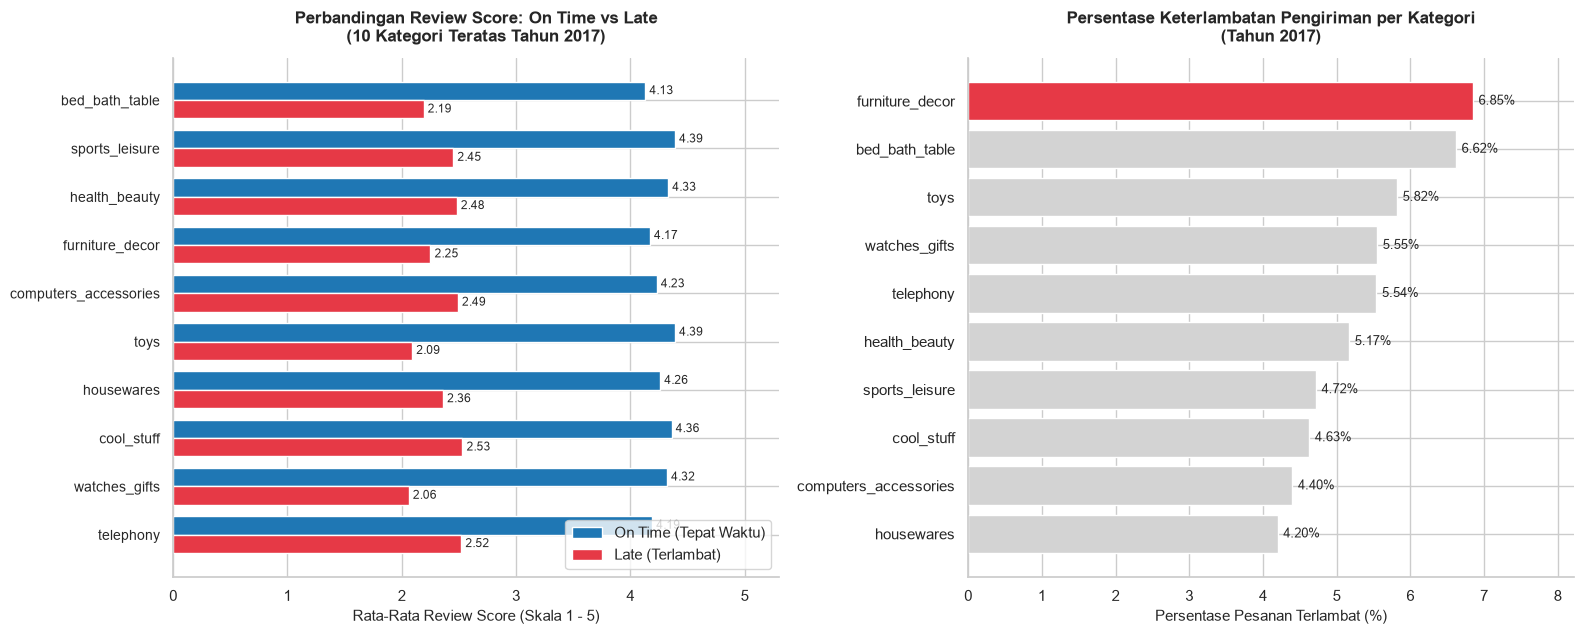

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Subplot 1: Grouped Horizontal Bar Chart (Review Score On Time vs Late)
y_pos = np.arange(len(q1_summary.index))
bar_h = 0.38

bars_on = axes[0].barh(
    y_pos - bar_h / 2,
    q1_summary["Score_On_Time"],
    height=bar_h,
    label="On Time (Tepat Waktu)",
    color="#1f77b4"
)
bars_lt = axes[0].barh(
    y_pos + bar_h / 2,
    q1_summary["Score_Late"],
    height=bar_h,
    label="Late (Terlambat)",
    color="#e63946"
)

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(q1_summary.index, fontsize=10)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 5.3)
axes[0].set_xlabel("Rata-Rata Review Score (Skala 1 - 5)", fontsize=11)
axes[0].set_title(
    "Perbandingan Review Score: On Time vs Late\n(10 Kategori Teratas Tahun 2017)",
    fontsize=12, fontweight="bold", pad=12
)
axes[0].bar_label(bars_on, fmt="%.2f", padding=3, fontsize=8.5)
axes[0].bar_label(bars_lt, fmt="%.2f", padding=3, fontsize=8.5)
axes[0].legend(loc="lower right", frameon=True)
sns.despine(top=True, right=True, ax=axes[0])

# Subplot 2: Persentase Keterlambatan per Kategori dengan Color Highlighting (#e63946 untuk tertinggi)
q1_sorted_delay = q1_summary.sort_values("Late_Rate (%)", ascending=False)
delay_colors = ["#e63946" if i == 0 else "#d3d3d3" for i in range(len(q1_sorted_delay))]

bars_delay = axes[1].barh(
    q1_sorted_delay.index,
    q1_sorted_delay["Late_Rate (%)"],
    color=delay_colors
)
axes[1].invert_yaxis()
axes[1].set_xlim(0, q1_sorted_delay["Late_Rate (%)"].max() * 1.2)
axes[1].set_xlabel("Persentase Pesanan Terlambat (%)", fontsize=11)
axes[1].set_title(
    "Persentase Keterlambatan Pengiriman per Kategori\n(Tahun 2017)",
    fontsize=12, fontweight="bold", pad=12
)
axes[1].bar_label(bars_delay, fmt="%.2f%%", padding=4, fontsize=9)
sns.despine(top=True, right=True, ax=axes[1])

plt.tight_layout()
plt.show()

**Insight:**
- Grafik *Grouped Horizontal Bar Chart* membuktikan secara konsisten bahwa **di seluruh 10 kategori produk teratas tahun 2017**, keterlambatan pengiriman menyebabkan penurunan tajam pada kepuasan pelanggan. Saat pesanan tiba tepat waktu (`On Time`), rata-rata `review_score` berada di rentang sangat tinggi (**4.13 – 4.39**). Sebaliknya, ketika pesanan mengalami keterlambatan (`Late`), rata-rata `review_score` jatuh drastis ke kisaran **2.06 – 2.53**.
- Penurunan kepuasan pelanggan paling parah terjadi pada kategori **`toys`** yang turun sebesar **2.30 poin** (dari **4.39** menjadi **2.09**).
- Dari sisi keandalan operasional kurir, kategori **`furniture_decor`** memiliki tingkat keterlambatan pengiriman tertinggi pada tahun 2017 yakni mencapai **6.85%**, sehingga harus menjadi prioritas utama dalam audit SLA logistik.

### Pertanyaan 2: Perbandingan GMV, AOV, dan Rata-Rata Cicilan antara Kartu Kredit (`credit_card`) dan `boleto` di 5 Negara Bagian Terbesar (Semester 1 2018)

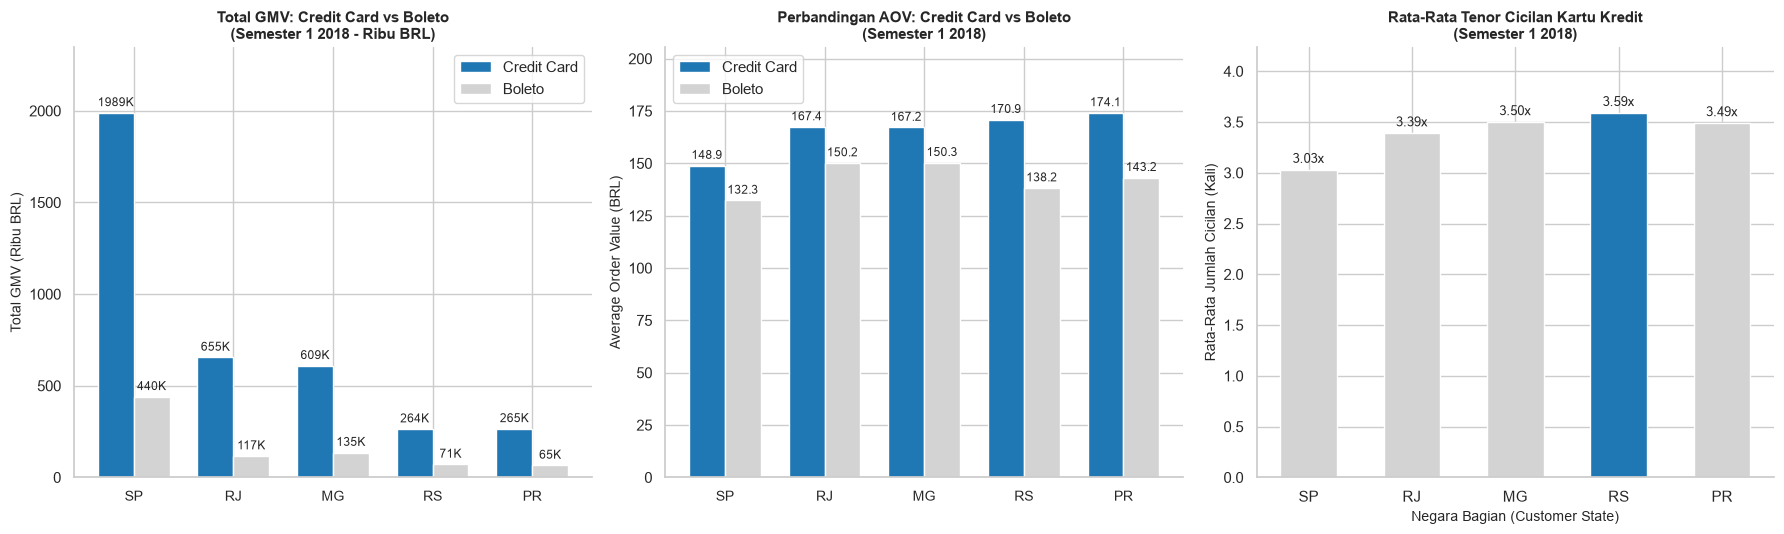

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

pivot_gmv = (
    q2_agg_table.pivot(index="customer_state", columns="payment_type", values="total_gmv_brl")
    .reindex(top5_states_h1_2018)
)
pivot_aov = (
    q2_agg_table.pivot(index="customer_state", columns="payment_type", values="aov_brl")
    .reindex(top5_states_h1_2018)
)
cc_installments = (
    q2_agg_table[q2_agg_table["payment_type"] == "credit_card"]
    .set_index("customer_state")["avg_installments"]
    .reindex(top5_states_h1_2018)
)

x = np.arange(len(top5_states_h1_2018))
width = 0.36

# Panel 1: Total GMV (dalam Ribu BRL)
b_gmv_cc = axes[0].bar(
    x - width / 2, pivot_gmv["credit_card"] / 1e3, width=width, label="Credit Card", color="#1f77b4"
)
b_gmv_bl = axes[0].bar(
    x + width / 2, pivot_gmv["boleto"] / 1e3, width=width, label="Boleto", color="#d3d3d3"
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(top5_states_h1_2018, fontsize=10)
axes[0].set_ylabel("Total GMV (Ribu BRL)", fontsize=10)
axes[0].set_title("Total GMV: Credit Card vs Boleto\n(Semester 1 2018 - Ribu BRL)", fontsize=11, fontweight="bold")
axes[0].bar_label(b_gmv_cc, fmt="%.0fK", padding=3, fontsize=8.5)
axes[0].bar_label(b_gmv_bl, fmt="%.0fK", padding=3, fontsize=8.5)
axes[0].set_ylim(0, (pivot_gmv["credit_card"].max() / 1e3) * 1.18)
axes[0].legend()
sns.despine(top=True, right=True, ax=axes[0])

# Panel 2: Average Order Value (AOV dalam BRL)
b_aov_cc = axes[1].bar(
    x - width / 2, pivot_aov["credit_card"], width=width, label="Credit Card", color="#1f77b4"
)
b_aov_bl = axes[1].bar(
    x + width / 2, pivot_aov["boleto"], width=width, label="Boleto", color="#d3d3d3"
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(top5_states_h1_2018, fontsize=10)
axes[1].set_ylabel("Average Order Value (BRL)", fontsize=10)
axes[1].set_title("Perbandingan AOV: Credit Card vs Boleto\n(Semester 1 2018)", fontsize=11, fontweight="bold")
axes[1].bar_label(b_aov_cc, fmt="%.1f", padding=3, fontsize=8.5)
axes[1].bar_label(b_aov_bl, fmt="%.1f", padding=3, fontsize=8.5)
axes[1].set_ylim(0, pivot_aov["credit_card"].max() * 1.18)
axes[1].legend()
sns.despine(top=True, right=True, ax=axes[1])

# Panel 3: Rata-rata jumlah cicilan Kartu Kredit (Highlight state tertinggi dengan #1f77b4)
max_inst_idx = int(cc_installments.values.argmax())
inst_colors = ["#1f77b4" if i == max_inst_idx else "#d3d3d3" for i in range(len(cc_installments))]
b_inst = axes[2].bar(top5_states_h1_2018, cc_installments.values, color=inst_colors, width=0.55)
axes[2].set_xlabel("Negara Bagian (Customer State)", fontsize=10)
axes[2].set_ylabel("Rata-Rata Jumlah Cicilan (Kali)", fontsize=10)
axes[2].set_title("Rata-Rata Tenor Cicilan Kartu Kredit\n(Semester 1 2018)", fontsize=11, fontweight="bold")
axes[2].bar_label(b_inst, fmt="%.2fx", padding=3, fontsize=9)
axes[2].set_ylim(0, cc_installments.max() * 1.18)
sns.despine(top=True, right=True, ax=axes[2])

plt.tight_layout()
plt.show()

**Insight:**
- **Dominasi Nilai Transaksi (GMV):** Di seluruh 5 negara bagian terbesar selama Semester 1 2018, metode pembayaran **`credit_card`** menghasilkan nilai GMV yang jauh melampaui `boleto` (hampir **4 kali lipat** secara agregat: **R\$ 3,781,422.53** vs **R\$ 828,760.52**). Di negara bagian **SP**, GMV kartu kredit mencapai **R\$ 1,988,886.09** sedangkan `boleto` sebesar **R\$ 440,022.44**.
- **Perbedaan Ukuran Keranjang Belanja (AOV):** Pelanggan yang membayar dengan **`credit_card`** secara konsisten memiliki *Average Order Value* (AOV) yang lebih tinggi di kelima negara bagian dibandingkan pengguna `boleto` (rata-rata **R\$ 157.74** vs **R\$ 138.68**).
- **Perilaku Cicilan Wilayah:** Tingginya AOV pada kartu kredit berkorelasi erat dengan pemanfaatan fitur cicilan (`payment_installments`), di mana pelanggan di negara bagian **`RS`** mencatatkan rata-rata tenor cicilan tertinggi sebesar **3.59 kali**, sedangkan wilayah **SP** memiliki rata-rata cicilan terendah karena tingginya proporsi pembelian barang kebutuhan harian bernilai menengah.

## Analisis Lanjutan (Advanced Analysis - Tanpa Machine Learning)

Untuk menggali pola perilaku pelanggan dan karakteristik spasial secara mendalam tanpa menggunakan algoritma *Machine Learning*, digunakan 3 pendekatan analitik berikut:
1. **RFM Analysis (*Recency, Frequency, Monetary*):** Mengukur nilai pelanggan berdasarkan:
   - *Recency*: Jumlah hari sejak transaksi terakhir pelanggan (`customer_unique_id`) terhadap tanggal referensi maksimum di dalam dataset.
   - *Frequency*: Total pesanan unik (`order_id`) yang pernah dilakukan oleh masing-masing pelanggan.
   - *Monetary*: Total nilai belanja (`payment_value` dalam BRL) yang dikontribusikan oleh pelanggan.
2. **Customer Segmentation via Manual Grouping / Binning:** Mengelompokkan pelanggan ke dalam 5 segmen strategis (`Champions`, `Loyal Customers`, `Potential Loyalists`, `At Risk`, dan `Lost`) menggunakan aturan kuartil dan *binning* (`pd.qcut` & `pd.cut`) tanpa algoritma *clustering* ML.
3. **Geospatial Analysis:** Memetakan kepadatan volume pesanan dan rata-rata keterlambatan pengiriman berdasarkan koordinat geografis (`geolocation_lat`, `geolocation_lng`) di seluruh wilayah Brasil.

Tanggal Referensi Analisis RFM: 2018-08-30


,count,mean,std,min,25%,50%,75%,max
Recency,93350.0,237.950070,152.589932,1.0,114.00,219.00,346.0000,714.00
Frequency,93350.0,1.033423,0.209106,1.0,1.00,1.00,1.0000,15.00
Monetary,93350.0,165.196388,226.322448,0.0,63.05,107.78,182.5475,13664.08


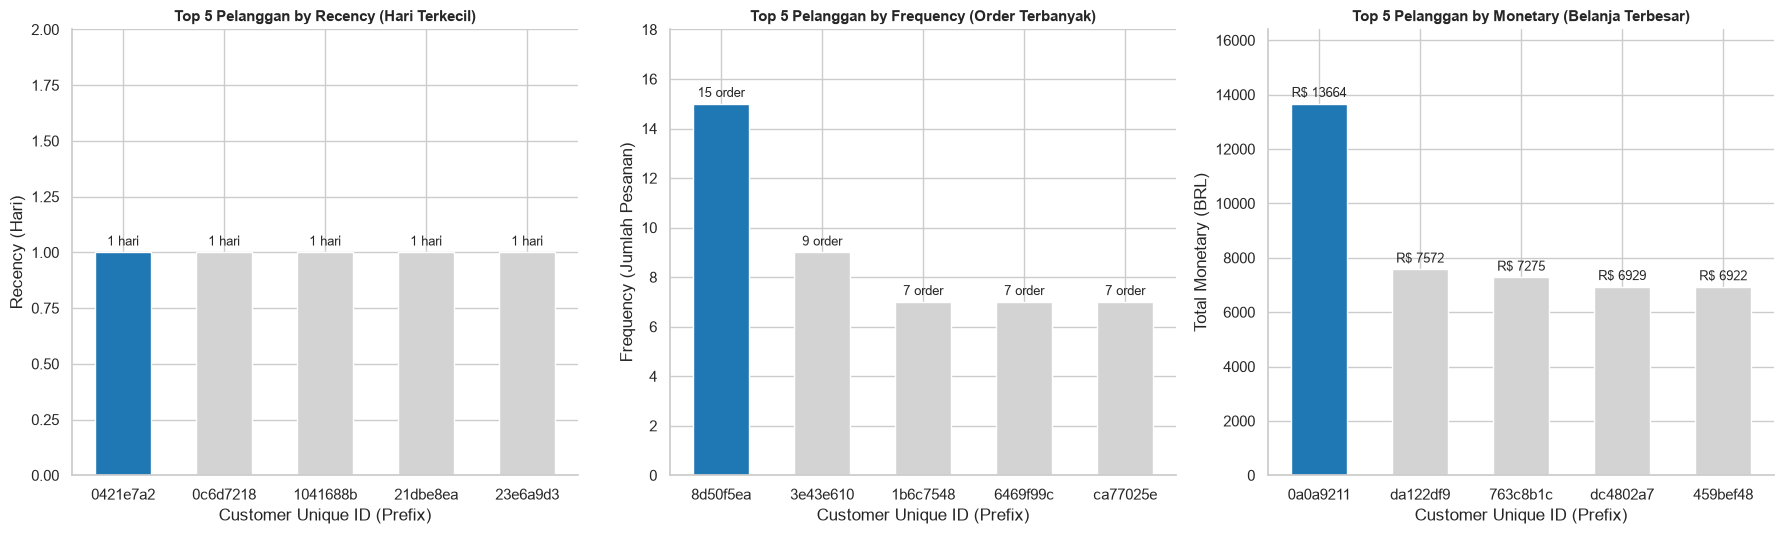

In [12]:
# 1. Perhitungan Metrik RFM pada level customer_unique_id
reference_date = order_level_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = (
    order_level_df.groupby("customer_unique_id")
    .agg(
        Recency=("order_purchase_timestamp", lambda x: (reference_date - x.max()).days),
        Frequency=("order_id", "nunique"),
        Monetary=("payment_value", "sum")
    )
    .reset_index()
)
rfm_df["short_id"] = rfm_df["customer_unique_id"].str[:8]

print(f"Tanggal Referensi Analisis RFM: {reference_date.strftime('%Y-%m-%d')}")
display(rfm_df.describe().T)

# Visualisasi Top 5 Pelanggan berdasarkan Recency, Frequency, dan Monetary
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Top 5 Recency (hari terkecil = paling baru bertransaksi)
top5_recency = rfm_df.nsmallest(5, "Recency")
colors_r = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(top5_recency))]
bars_r = axes[0].bar(top5_recency["short_id"], top5_recency["Recency"], color=colors_r, width=0.55)
axes[0].set_title("Top 5 Pelanggan by Recency (Hari Terkecil)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Customer Unique ID (Prefix)")
axes[0].set_ylabel("Recency (Hari)")
axes[0].bar_label(bars_r, fmt="%d hari", padding=3, fontsize=9)
axes[0].set_ylim(0, max(top5_recency["Recency"].max() * 1.25, 2))
sns.despine(top=True, right=True, ax=axes[0])

# Top 5 Frequency (jumlah order terbanyak)
top5_freq = rfm_df.nlargest(5, "Frequency")
colors_f = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(top5_freq))]
bars_f = axes[1].bar(top5_freq["short_id"], top5_freq["Frequency"], color=colors_f, width=0.55)
axes[1].set_title("Top 5 Pelanggan by Frequency (Order Terbanyak)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Customer Unique ID (Prefix)")
axes[1].set_ylabel("Frequency (Jumlah Pesanan)")
axes[1].bar_label(bars_f, fmt="%d order", padding=3, fontsize=9)
axes[1].set_ylim(0, top5_freq["Frequency"].max() * 1.2)
sns.despine(top=True, right=True, ax=axes[1])

# Top 5 Monetary (total belanja terbesar)
top5_monetary = rfm_df.nlargest(5, "Monetary")
colors_m = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(top5_monetary))]
bars_m = axes[2].bar(top5_monetary["short_id"], top5_monetary["Monetary"], color=colors_m, width=0.55)
axes[2].set_title("Top 5 Pelanggan by Monetary (Belanja Terbesar)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Customer Unique ID (Prefix)")
axes[2].set_ylabel("Total Monetary (BRL)")
axes[2].bar_label(bars_m, fmt="R$ %.0f", padding=3, fontsize=9)
axes[2].set_ylim(0, top5_monetary["Monetary"].max() * 1.2)
sns.despine(top=True, right=True, ax=axes[2])

plt.tight_layout()
plt.show()

,Segment,total_customers,avg_recency,avg_frequency,avg_monetary,share (%)
0,Lost,23310,451.493779,1.026898,164.227470,24.97
1,At Risk,23199,277.371956,1.031208,163.096109,24.85
2,Potential Loyalists,22755,112.275939,1.000000,63.002272,24.38
3,Champions,12454,112.048017,1.142043,380.137154,13.34
4,Loyal Customers,11632,112.042813,1.000000,141.113228,12.46


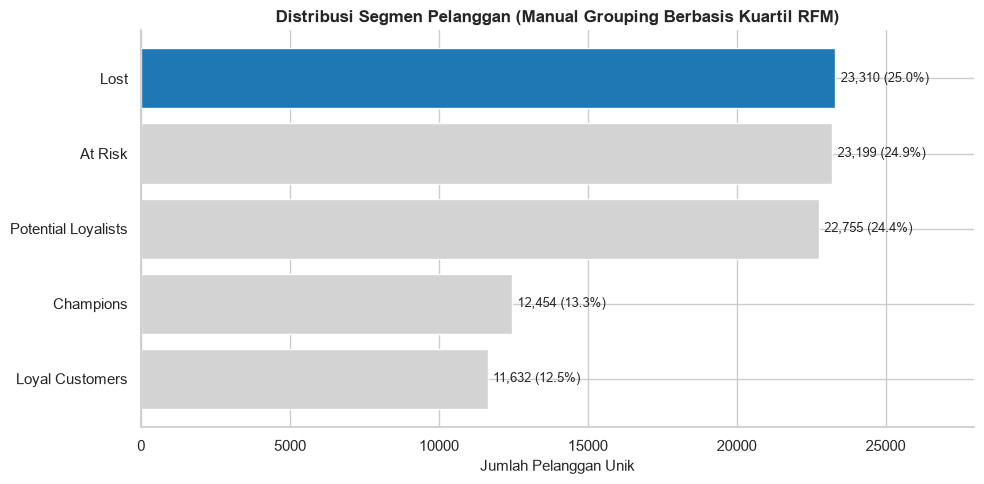

In [13]:
# 2. Manual Grouping / Binning Pelanggan Berdasarkan Aturan Kuartil Skor RFM
rfm_df["R_Score"] = pd.qcut(rfm_df["Recency"], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["F_Score"] = pd.cut(rfm_df["Frequency"], bins=[0, 1, 2, 100], labels=[2, 3, 4]).astype(int)
rfm_df["M_Score"] = pd.qcut(rfm_df["Monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)

def manual_segment_assignment(row):
    r, f, m = row["R_Score"], row["F_Score"], row["M_Score"]
    if r >= 3 and (f >= 3 or m == 4):
        return "Champions"
    elif r >= 3 and m >= 3:
        return "Loyal Customers"
    elif r >= 3 and m <= 2:
        return "Potential Loyalists"
    elif r == 2:
        return "At Risk"
    else:
        return "Lost"

rfm_df["Segment"] = rfm_df.apply(manual_segment_assignment, axis=1)

segment_summary = (
    rfm_df.groupby("Segment")
    .agg(
        total_customers=("customer_unique_id", "count"),
        avg_recency=("Recency", "mean"),
        avg_frequency=("Frequency", "mean"),
        avg_monetary=("Monetary", "mean")
    )
    .sort_values("total_customers", ascending=False)
    .reset_index()
)
segment_summary["share (%)"] = (segment_summary["total_customers"] / len(rfm_df) * 100).round(2)
display(segment_summary)

# Visualisasi Horizontal Bar Chart Distribusi Segmen Pelanggan
fig, ax = plt.subplots(figsize=(10, 5))
seg_colors = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(segment_summary))]
bars_seg = ax.barh(segment_summary["Segment"], segment_summary["total_customers"], color=seg_colors)
ax.invert_yaxis()
ax.set_xlabel("Jumlah Pelanggan Unik", fontsize=11)
ax.set_title("Distribusi Segmen Pelanggan (Manual Grouping Berbasis Kuartil RFM)", fontsize=12, fontweight="bold")
ax.bar_label(
    bars_seg,
    labels=[f"{cnt:,} ({pct:.1f}%)" for cnt, pct in zip(segment_summary["total_customers"], segment_summary["share (%)"])],
    padding=4,
    fontsize=9.5
)
ax.set_xlim(0, segment_summary["total_customers"].max() * 1.2)
sns.despine(top=True, right=True, ax=ax)
plt.tight_layout()
plt.show()

,customer_state,lat,lng,total_orders,late_rate_pct,avg_delay_days
0,AL,-9.6330,-35.75460,396,21.464646,-8.679293
1,MA,-2.5615,-44.27040,714,17.226891,-9.638655
2,SE,-10.9304,-37.07135,334,15.269461,-9.988024
3,PI,-5.0911,-42.76600,473,13.953488,-11.336152
4,CE,-3.7959,-38.58070,1275,13.803922,-10.777255
5,RR,2.8214,-60.67920,41,12.195122,-17.292683
6,RJ,-22.8870,-43.24320,12337,12.118019,-11.763638
7,BA,-12.9489,-38.78650,3247,12.103480,-10.824761
8,PA,-1.4502,-48.47360,942,11.252654,-14.049894
9,ES,-20.2993,-40.31430,1989,10.608346,-10.534439


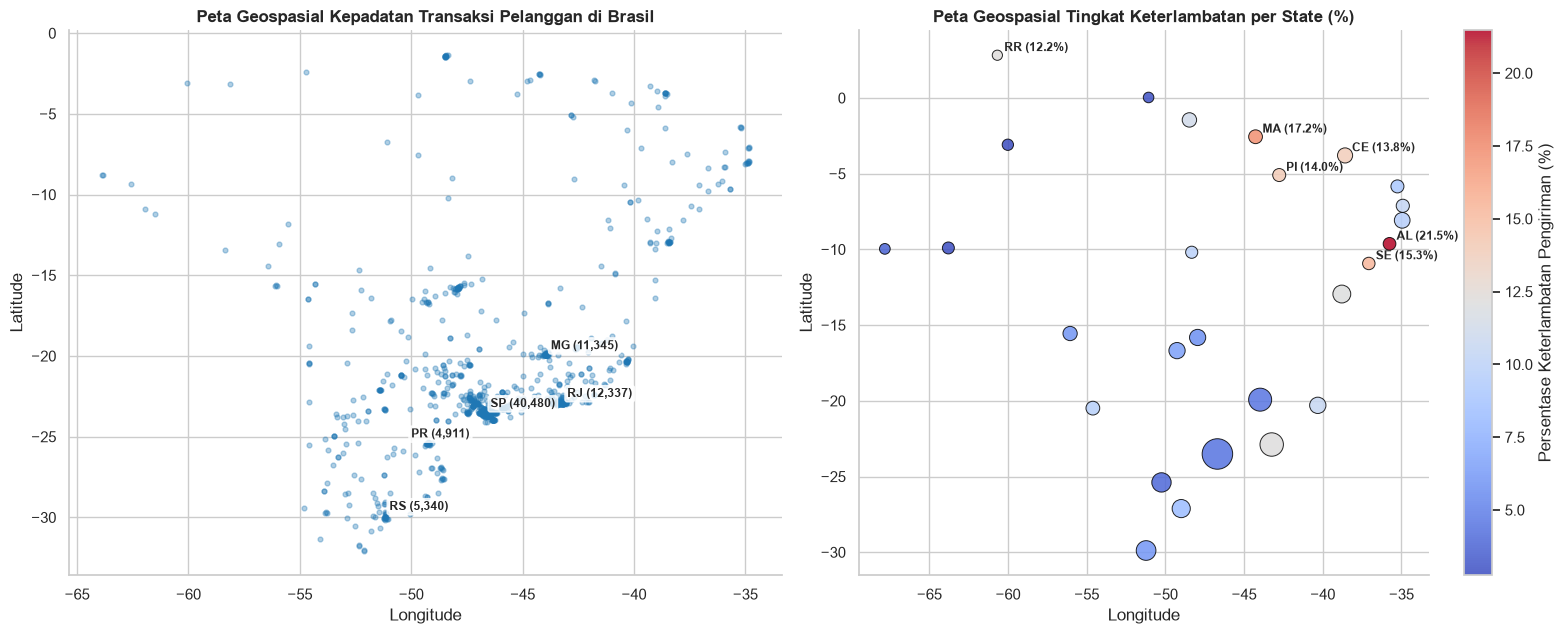

In [14]:
# 3. Geospatial Analysis: Kepadatan Transaksi dan Rata-Rata Keterlambatan di Wilayah Brasil
geo_valid = order_level_df.dropna(subset=["geolocation_lat", "geolocation_lng"]).copy()
# Filter koordinat di dalam batas geografis daratan Brasil
geo_brazil = geo_valid[
    (geo_valid["geolocation_lat"].between(-34.0, 5.5))
    & (geo_valid["geolocation_lng"].between(-74.0, -34.0))
].copy()

state_geo_summary = (
    geo_brazil.groupby("customer_state")
    .agg(
        lat=("geolocation_lat", "median"),
        lng=("geolocation_lng", "median"),
        total_orders=("order_id", "nunique"),
        late_rate_pct=("delivery_status", lambda s: (s == "Late").mean() * 100),
        avg_delay_days=("delivery_delay_days", "mean")
    )
    .sort_values("late_rate_pct", ascending=False)
    .reset_index()
)
display(state_geo_summary.head(10))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Peta 1: Sebaran Kepadatan Transaksi Pelanggan di Brasil (Sample maksimal 1.000 titik agar ringan)
geo_sample = geo_brazil.sample(n=min(1000, len(geo_brazil)), random_state=42)
axes[0].scatter(
    geo_sample["geolocation_lng"],
    geo_sample["geolocation_lat"],
    alpha=0.35,
    s=12,
    color="#1f77b4"
)
for _, r in state_geo_summary.nlargest(5, "total_orders").iterrows():
    axes[0].annotate(
        f"{r['customer_state']} ({int(r['total_orders']):,})",
        (r["lng"], r["lat"]),
        fontsize=8.5,
        fontweight="bold",
        xytext=(4, 4),
        textcoords="offset points",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8)
    )
axes[0].set_title("Peta Geospasial Kepadatan Transaksi Pelanggan di Brasil", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
sns.despine(top=True, right=True, ax=axes[0])

# Peta 2: Tingkat Keterlambatan Pengiriman per Negara Bagian (Bubble Map)
scatter_delay = axes[1].scatter(
    state_geo_summary["lng"],
    state_geo_summary["lat"],
    s=np.sqrt(state_geo_summary["total_orders"]) * 2.2 + 40,
    c=state_geo_summary["late_rate_pct"],
    cmap="coolwarm",
    alpha=0.85,
    edgecolors="black",
    linewidth=0.7
)
cbar = plt.colorbar(scatter_delay, ax=axes[1])
cbar.set_label("Persentase Keterlambatan Pengiriman (%)")

for _, r in state_geo_summary.head(6).iterrows():
    axes[1].annotate(
        f"{r['customer_state']} ({r['late_rate_pct']:.1f}%)",
        (r["lng"], r["lat"]),
        fontsize=8.5,
        fontweight="bold",
        xytext=(5, 3),
        textcoords="offset points"
    )
axes[1].set_title("Peta Geospasial Tingkat Keterlambatan per State (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
sns.despine(top=True, right=True, ax=axes[1])

plt.tight_layout()
plt.show()

**Insight:**
- **RFM Analysis:** Dari total **93,350 pelanggan unik**, rata-rata *Recency* berada pada **238.0 hari**, dengan rata-rata *Monetary* sebesar **R\$ 165.20**. Pelanggan dengan frekuensi tertinggi mencatatkan **15 pesanan**, sementara nilai belanja kumulatif tertinggi mencapai **R\$ 13,664.08**. Namun, sebanyak **97.00%** pelanggan baru melakukan 1 kali transaksi (*repeat order rate* hanya **3.00%**).
- **Manual Grouping (Customer Segmentation):** Berdasarkan pengelompokan kuartil RFM, segmen terbesar adalah **`Lost`** sebanyak **23,310 pelanggan (24.97%)**, diikuti oleh **`At Risk`** (**23,199 pelanggan, 24.85%**) dan **`Potential Loyalists`** (**22,755 pelanggan, 24.38%**). Adapun pelanggan bernilai tinggi berada pada segmen **`Champions`** (**12,454 pelanggan, 13.34%**) dan **`Loyal Customers`** (**11,632 pelanggan, 12.46%**).
- **Geospatial Analysis:** Kepadatan transaksi terpusat di wilayah Tenggara dan Selatan Brasil (**SP, RJ, MG, RS, PR**). Sebaliknya, tingkat keterlambatan pengiriman tertinggi justru terkonsentrasi di wilayah Timur Laut (*Northeast*) yang berjarak jauh dari pusat *seller* di São Paulo, terutama di negara bagian **`AL` (21.46% terlambat)** dan **`MA` (17.23% terlambat)**.

## Conclusion & Recommendation

### Conclusion
1. **Jawaban Pertanyaan Bisnis 1 (Operasional Logistik & Kepuasan Pelanggan Tahun 2017):**
   Keterlambatan pengiriman terbukti memberikan dampak negatif yang sangat signifikan terhadap kepuasan pelanggan di seluruh 10 kategori produk dengan volume pesanan tertinggi sepanjang tahun 2017. Secara keseluruhan pada 10 kategori utama tersebut, pesanan yang dikirim tepat waktu (`On Time`) memperoleh rata-rata skor ulasan (`review_score`) sebesar **4.27 / 5.00**, sedangkan pesanan yang mengalami keterlambatan (`Late`) anjlok menjadi **2.32 / 5.00**—terjadi penurunan rata-rata sebesar **1.95 poin** (**45.7%**). Penurunan skor ulasan paling tajam terjadi pada kategori **`toys`** dengan selisih **2.30 poin**, sementara kategori dengan persentase keterlambatan pengiriman tertinggi di tahun 2017 adalah **`furniture_decor`** yang mencapai **6.85%**.

2. **Jawaban Pertanyaan Bisnis 2 (Perilaku Pembayaran & Nilai Transaksi Wilayah Semester 1 2018):**
   Selama Semester 1 tahun 2018 (Januari – Juni 2018) di 5 negara bagian dengan transaksi terbesar (**`SP, RJ, MG, RS, PR`**), metode pembayaran Kartu Kredit (**`credit_card`**) mendominasi secara mutlak dengan total *Gross Merchandise Value* (GMV) mencapai **R\$ 3,781,422.53**, atau hampir **4 kali lipat** dibandingkan metode **`boleto`** yang mencatatkan GMV sebesar **R\$ 828,760.52**. Selain volume transaksi yang lebih besar, pengguna `credit_card` juga mencatatkan *Average Order Value* (AOV) yang lebih tinggi (**R\$ 157.74** vs **R\$ 138.68** pada `boleto`), yang ditopang oleh pemanfaatan fitur cicilan dengan rata-rata **3.23 kali angsuran** (dengan rata-rata tenor tertinggi berada di negara bagian **`RS`** sebesar **3.59 kali**).

---

### Recommendation (Action Items)
1. **Rekalibrasi SLA Estimasi Pengiriman & Diversifikasi Mitra Logistik di Kategori dan Wilayah Rawan Terlambat:**
   Tim operasional logistik perlu mengevaluasi ulang kontrak SLA kurir pada kategori **`furniture_decor`** dan **`toys`**, serta membuka *fulfillment hub* atau bermitra dengan kurir regional di wilayah Timur Laut Brasil (khususnya **`AL`** dan **`MA`** yang memiliki rasio keterlambatan > 20%). Selain itu, sistem perlu memberikan *buffer* estimasi waktu tiba yang lebih akurat dan mengirimkan notifikasi kompensasi proaktif (*voucher* diskon) apabila paket terdeteksi melewati batas estimasi sebelum pelanggan memberikan ulasan bintang 1.
2. **Program Promo Cicilan 0% Kartu Kredit & Insentif Konversi Pembayaran Boleto di 5 Negara Bagian Utama:**
   Tim *marketing* dan *partnership* perbankan disarankan meluncurkan kampanye **Cicilan 0% untuk tenor 3x–6x** khusus transaksi kartu kredit dengan nilai keranjang di atas R\$ 180 di wilayah **SP, RJ, MG, RS, dan PR** guna mendongkrak AOV lebih lanjut. Sementara untuk segmen pengguna `boleto`, berikan diskon *instant checkout* sebesar 3%–5% atau integrasikan metode pembayaran instan agar pelanggan tetap terdorong berbelanja dengan nilai keranjang yang lebih tinggi.
3. **Kampanye Retensi Terarah Berbasis Segmen RFM (*Win-Back* & *Second-Order Incentive*):**
   Mengingat **97.00%** pelanggan hanya bertransaksi satu kali dan terdapat **22,755 pelanggan** pada segmen *Potential Loyalists*, tim CRM perlu menerapkan otomatisasi *voucher repeat order* dalam 14–30 hari pasca pembelian pertama untuk mengonversi *Potential Loyalists* menjadi *Champions*, serta mengirimkan kampanye *re-engagement* khusus bagi **23,199 pelanggan** di segmen *At Risk*.